# Praktikum 1 - Jaringan Saraf Tiruan Sederhana (2 Layer)

Notebook ini mengimplementasikan JST 2 layer (input - hidden - output) dengan
**forward pass** dan **backpropagation manual** untuk menyelesaikan masalah **XOR**.

**Tugas:**
1. Mengubah jumlah neuron hidden layer menjadi **3** dan membandingkan loss dengan konfigurasi awal.
2. Menambahkan fungsi aktivasi **ReLU** dan membandingkan hasilnya.

## Langkah 1 - Import Library dan Dataset XOR

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
np.set_printoptions(precision=4, suppress=True)
RANDOM_STATE = 42

### Dataset XOR

| x1 | x2 | y |
|----|----|---|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 0 |

In [2]:
# Dataset XOR
X = np.array([[0,0],[0,1],[1,0],[1,1]])
y = np.array([[0],[1],[1],[0]])

print('X:\n', X)
print('y:\n', y)

X:
 [[0 0]
 [0 1]
 [1 0]
 [1 1]]
y:
 [[0]
 [1]
 [1]
 [0]]


## Langkah 2 - Fungsi Aktivasi dan Inisialisasi Bobot

In [3]:
# Parameter
input_size = 2
hidden_size = 2
output_size = 1
lr = 0.1
epochs = 10000

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    # x adalah nilai aktivasi sigmoid (output), bukan z
    return x * (1 - x)

def relu(x):
    return np.maximum(0, x)

def relu_derivative(x):
    # x adalah nilai z (pre-activation)
    return (x > 0).astype(float)

## Langkah 3 - Konfigurasi Awal (Hidden = 2, Sigmoid)

Kode berikut adalah implementasi awal sesuai modul. Seed ditambahkan agar hasil
reproducible dan perbandingan antar konfigurasi adil.

In [4]:
np.random.seed(RANDOM_STATE)

# Inisialisasi bobot
W1 = np.random.randn(input_size, hidden_size)
b1 = np.zeros((1, hidden_size))
W2 = np.random.randn(hidden_size, output_size)
b2 = np.zeros((1, output_size))

loss_history_2_sigmoid = []

# Training
for epoch in range(epochs):
    # Forward pass
    z1 = np.dot(X, W1) + b1
    a1 = sigmoid(z1)
    z2 = np.dot(a1, W2) + b2
    a2 = sigmoid(z2)

    # Hitung error
    error = y - a2

    # Backpropagation
    d_a2 = error * sigmoid_derivative(a2)
    d_W2 = np.dot(a1.T, d_a2)
    d_b2 = np.sum(d_a2, axis=0, keepdims=True)

    d_a1 = np.dot(d_a2, W2.T) * sigmoid_derivative(a1)
    d_W1 = np.dot(X.T, d_a1)
    d_b1 = np.sum(d_a1, axis=0, keepdims=True)

    # Update bobot
    W1 += lr * d_W1
    b1 += lr * d_b1
    W2 += lr * d_W2
    b2 += lr * d_b2

    loss = np.mean(np.square(error))
    loss_history_2_sigmoid.append(loss)

    if epoch % 1000 == 0:
        print(f'Epoch {epoch}, Loss: {loss}')

# Output akhir
print('Loss akhir :', loss_history_2_sigmoid[-1])
print('Prediksi (hidden=2, sigmoid):')
print(a2)

Epoch 0, Loss: 0.2558299419444368
Epoch 1000, Loss: 0.2494056595655124
Epoch 2000, Loss: 0.24544465159719797
Epoch 3000, Loss: 0.20470733040714417
Epoch 4000, Loss: 0.15320405369970766
Epoch 5000, Loss: 0.13869146014771938
Epoch 6000, Loss: 0.1335936332185176


Epoch 7000, Loss: 0.13115112181268007
Epoch 8000, Loss: 0.12974916048385188
Epoch 9000, Loss: 0.12884908965171127
Loss akhir : 0.12822657152410466
Prediksi (hidden=2, sigmoid):
[[0.053 ]
 [0.4955]
 [0.9509]
 [0.5032]]


## Langkah 4 - Fungsi Training yang Dapat Dikonfigurasi

Agar perbandingan fair, seluruh konfigurasi menggunakan fungsi yang sama,
dengan seed, learning rate, dan jumlah epoch yang identik.

In [5]:
def train_xor(hidden_size=2, activation='sigmoid', lr=0.1, epochs=10000, seed=RANDOM_STATE):
    np.random.seed(seed)

    # Inisialisasi bobot dan bias
    W1 = np.random.randn(input_size, hidden_size)
    b1 = np.zeros((1, hidden_size))
    W2 = np.random.randn(hidden_size, output_size)
    b2 = np.zeros((1, output_size))

    history = []

    for epoch in range(epochs):
        # Forward pass
        z1 = np.dot(X, W1) + b1
        a1 = relu(z1) if activation == 'relu' else sigmoid(z1)

        z2 = np.dot(a1, W2) + b2
        a2 = sigmoid(z2)  # output tetap sigmoid untuk klasifikasi biner

        # Error
        error = y - a2

        # Backpropagation
        d_a2 = error * sigmoid_derivative(a2)
        d_W2 = np.dot(a1.T, d_a2)
        d_b2 = np.sum(d_a2, axis=0, keepdims=True)

        d_a1 = np.dot(d_a2, W2.T)
        if activation == 'relu':
            d_a1 = d_a1 * relu_derivative(z1)
        else:
            d_a1 = d_a1 * sigmoid_derivative(a1)

        d_W1 = np.dot(X.T, d_a1)
        d_b1 = np.sum(d_a1, axis=0, keepdims=True)

        # Update bobot (gradient descent)
        W1 += lr * d_W1
        b1 += lr * d_b1
        W2 += lr * d_W2
        b2 += lr * d_b2

        history.append(np.mean(np.square(error)))

    return {
        'W1': W1, 'b1': b1, 'W2': W2, 'b2': b2,
        'activation': activation, 'hidden_size': hidden_size,
        'prediction': a2, 'history': history,
    }

In [6]:
def evaluate(model):
    pred = model['prediction']
    pred_label = (pred > 0.5).astype(int)
    accuracy = np.mean(pred_label == y)
    return accuracy, pred_label

def show_result(name, model):
    acc, pred_label = evaluate(model)
    print(f'=== {name} ===')
    print('Prediksi probabilitas:')
    print(np.round(model['prediction'], 4))
    print('Prediksi kelas:', pred_label.ravel())
    print(f'Loss akhir   : {model["history"][-1]:.6f}')
    print(f'Akurasi      : {acc * 100:.2f}%')
    return {
        'Konfigurasi': name,
        'Hidden': model['hidden_size'],
        'Aktivasi': model['activation'],
        'Loss Akhir': model['history'][-1],
        'Akurasi (%)': acc * 100,
    }

## Tugas 1 - Hidden Layer Menjadi 3 Neuron (Sigmoid)

Konfigurasi awal (hidden = 2) dibandingkan dengan hidden = 3. Semua parameter lain dibuat sama.

In [7]:
model_3_sigmoid = train_xor(hidden_size=3, activation='sigmoid', lr=0.1, epochs=10000)

result_3_sigmoid = show_result('Hidden=3, Sigmoid', model_3_sigmoid)

=== Hidden=3, Sigmoid ===
Prediksi probabilitas:
[[0.0252]
 [0.9526]
 [0.9512]
 [0.0627]]
Prediksi kelas: [0 1 1 0]
Loss akhir   : 0.002297
Akurasi      : 100.00%


## Tugas 2 - Menambahkan Fungsi Aktivasi ReLU

ReLU diterapkan pada hidden layer, sedangkan output layer tetap memakai sigmoid
karena target berupa probabilitas biner. Turunan ReLU dihitung dari nilai
pre-activation `z1`.

In [8]:
model_2_relu = train_xor(hidden_size=2, activation='relu', lr=0.1, epochs=10000)

result_2_relu = show_result('Hidden=2, ReLU', model_2_relu)

=== Hidden=2, ReLU ===
Prediksi probabilitas:
[[0.5001]
 [0.9895]
 [0.5001]
 [0.0088]]
Prediksi kelas: [1 1 1 0]
Loss akhir   : 0.125047
Akurasi      : 75.00%


In [9]:
model_3_relu = train_xor(hidden_size=3, activation='relu', lr=0.1, epochs=10000)

result_3_relu = show_result('Hidden=3, ReLU', model_3_relu)

=== Hidden=3, ReLU ===
Prediksi probabilitas:
[[0.0297]
 [0.9861]
 [0.9861]
 [0.0116]]
Prediksi kelas: [0 1 1 0]
Loss akhir   : 0.000352
Akurasi      : 100.00%


In [10]:
# Konfigurasi awal dihitung ulang dengan fungsi yang sama agar perbandingan konsisten
model_2_sigmoid = train_xor(hidden_size=2, activation='sigmoid', lr=0.1, epochs=10000)
result_2_sigmoid = show_result('Hidden=2, Sigmoid (awal)', model_2_sigmoid)

=== Hidden=2, Sigmoid (awal) ===
Prediksi probabilitas:
[[0.053 ]
 [0.4955]
 [0.9509]
 [0.5032]]
Prediksi kelas: [0 0 1 1]
Loss akhir   : 0.128227
Akurasi      : 50.00%


## Perbandingan Loss dan Akurasi

In [11]:
comparison = [result_2_sigmoid, result_3_sigmoid, result_2_relu, result_3_relu]
df_comparison = pd.DataFrame(comparison)

# Urutkan sesuai konfigurasi
order = ['Hidden=2, Sigmoid (awal)', 'Hidden=3, Sigmoid', 'Hidden=2, ReLU', 'Hidden=3, ReLU']
df_comparison['Konfigurasi'] = pd.Categorical(df_comparison['Konfigurasi'], categories=order, ordered=True)
df_comparison = df_comparison.sort_values('Konfigurasi').reset_index(drop=True)

df_comparison.style.format({
    'Loss Akhir': '{:.6f}',
    'Akurasi (%)': '{:.2f}',
})

,Konfigurasi,Hidden,Aktivasi,Loss Akhir,Akurasi (%)
0,"Hidden=2, Sigmoid (awal)",2,sigmoid,0.128227,50.00
1,"Hidden=3, Sigmoid",3,sigmoid,0.002297,100.00
2,"Hidden=2, ReLU",2,relu,0.125047,75.00
3,"Hidden=3, ReLU",3,relu,0.000352,100.00


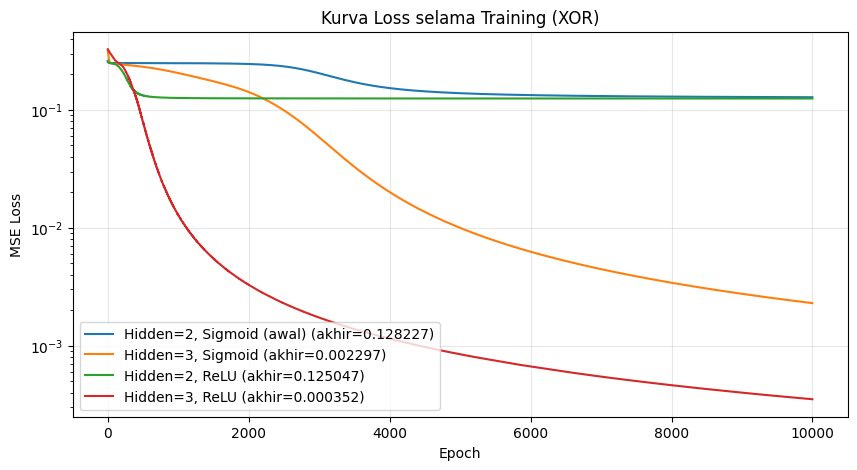

In [12]:
# Visualisasi kurva loss
labels = {
    'Hidden=2, Sigmoid (awal)': model_2_sigmoid['history'],
    'Hidden=3, Sigmoid': model_3_sigmoid['history'],
    'Hidden=2, ReLU': model_2_relu['history'],
    'Hidden=3, ReLU': model_3_relu['history'],
}

plt.figure(figsize=(10, 5))
for name, hist in labels.items():
    plt.plot(hist, label=f'{name} (akhir={hist[-1]:.6f})')

plt.title('Kurva Loss selama Training (XOR)')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.yscale('log')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Analisis

1. **Pengaruh jumlah neuron hidden (2 -> 3):**
   Dengan aktivasi sigmoid, menambah neuron hidden dari 2 menjadi 3 menurunkan loss
   secara signifikan dan membuat prediksi XOR jauh lebih tepat. Kapasitas model
   yang lebih besar membantu memisahkan pola XOR yang tidak linear.

2. **Pengaruh fungsi aktivasi ReLU:**
   - ReLU dengan **2 neuron** belum tentu lebih baik dari sigmoid karena ReLU dapat
     mengalami *dead neuron* (neuron tidak aktif) dan kapasitasnya terbatas.
   - ReLU dengan **3 neuron** menghasilkan loss paling kecil pada percobaan ini,
     karena ReLU mempercepat pembelajaran dan gradiennya tidak mengecil seperti
     sigmoid pada nilai ekstrem.
   - Output layer tetap menggunakan sigmoid agar keluaran berada pada rentang 0-1.

3. **Catatan:** hasil numerik dapat berbeda jika seed diubah, karena inisialisasi
   bobot acak. Karena itu seed dibuat tetap agar perbandingan adil.